# TensorFlow 기반 자연환경 이미지 분류 AI 개발

**실습 과제 답안 노트북 (Google Colab 권장)**

데이터: [Intel Image Classification](https://www.kaggle.com/datasets/puneet6060/intel-image-classification)  
클래스 6개: **건물(buildings), 숲(forest), 빙하(glacier), 산(mountain), 바다(sea), 거리(street)**  
모델: GPU가 없어도 학습 가능한 **간단한 CNN**

이 노트북은 초보 기획자도 흐름을 따라갈 수 있도록, 과제 요구사항을 단계별로 나눠 작성했습니다.  
**런타임 → 런타임 유형 변경 → GPU(T4)** 를 켜면 학습이 훨씬 빨라집니다. CPU만으로도 실행할 수 있도록 모델과 배치 크기를 작게 두었습니다.


## 0. 전체 개발 순서와 단계별 목적

| 단계 | 할 일 | 목적 |
|------|--------|------|
| 0 | 한글 폰트 설치, 라이브러리 준비 | Colab 그래프에서 한글이 깨지지 않게 함 |
| 1 | 데이터셋 폴더 구조·이미지 개수 확인 | 학습/테스트가 클래스별로 나뉘었는지 파악 |
| 2 | 학습·테스트 이미지 불러오기 | 폴더 이름을 정답 라벨로 사용 |
| 3 | 150×150 리사이즈 | 입력 크기를 모델에 맞춤 |
| 4 | 픽셀 값 0~1 정규화 | 학습이 안정적으로 되도록 스케일 통일 |
| 5 | CNN 생성 (Conv2D, MaxPooling2D, GAP, Dense) | 이미지의 지역 패턴을 학습 |
| 6 | 컴파일·학습 | 손실을 줄이며 가중치를 갱신 |
| 7 | 학습/검증 정확도 그래프 | 과적합 여부를 눈으로 확인 |
| 8 | 테스트 Accuracy | 한 번도 학습에 안 쓴 데이터로 성능 측정 |
| 9 | 테스트 이미지 10장 비교 | 맞춘 사례·틀린 사례를 직관적으로 확인 |
| 10 | 혼동행렬 | 어떤 클래스를 어떤 클래스로 혼동하는지 분석 |
| 11 | `nature_classifier.keras` 저장 | 이후 서비스에 모델을 재사용 |
| 12 | 오분류 분석 + 서비스 기획 요약 | 수치를 기획 언어로 해석 |

> 클래스 번호(0~5)는 우열이 아닙니다. 폴더 이름 알파벳 순으로 붙은 이름표입니다.


## 0-1. 환경 확인과 Colab 한글 폰트 설치

그래프 제목·축 라벨·범례에 한글을 쓰려면 **나눔고딕**이 필요합니다.  
Colab은 기본 폰트에 한글이 없어, 아래 셀에서 패키지를 설치하고 폰트 캐시를 새로고칩니다.

- 설치 후에도 한글이 깨지면 **런타임 → 런타임 다시 시작** 후, 이 셀부터 다시 실행하세요.
- Windows 로컬에서는 `apt-get`을 건너뛰고 **맑은 고딕**을 사용합니다.


In [1]:
# 코랩(Colab)인지 먼저 확인합니다.
import sys
import subprocess

IN_COLAB = "google.colab" in sys.modules
print("실행 환경:", "Google Colab" if IN_COLAB else "로컬 Python")

# 필요 라이브러리 (Colab에는 tensorflow가 이미 있습니다)
# %pip install -q tensorflow numpy matplotlib scikit-learn kagglehub

if IN_COLAB:
    # Colab 리눅스에 나눔 글꼴을 설치합니다. (그래프 한글 깨짐 방지)
    !sudo apt-get install -y fonts-nanum
    !sudo fc-cache -fv
    !rm -rf ~/.cache/matplotlib
    print("나눔 폰트 설치 및 캐시 갱신 완료")
    print("한글이 깨지면 런타임을 다시 시작한 뒤, 이 셀부터 재실행하세요.")
else:
    print("로컬 환경입니다. Windows는 맑은 고딕, macOS는 AppleGothic을 사용합니다.")


실행 환경: Google Colab
Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
The following NEW packages will be installed:
  fonts-nanum
0 upgraded, 1 newly installed, 0 to remove and 33 not upgraded.
Need to get 10.3 MB of archives.
After this operation, 34.1 MB of additional disk space will be used.
Get:1 http://archive.ubuntu.com/ubuntu noble/universe amd64 fonts-nanum all 20200506-1 [10.3 MB]
Fetched 10.3 MB in 3s (2,993 kB/s)
debconf: unable to initialize frontend: Dialog
debconf: (No usable dialog-like program is installed, so the dialog based frontend cannot be used. at /usr/share/perl5/Debconf/FrontEnd/Dialog.pm line 79, <STDIN> line 1.)
debconf: falling back to frontend: Readline
debconf: unable to initialize frontend: Readline
debconf: (This frontend requires a controlling tty.)
debconf: falling back to frontend: Teletype
dpkg-preconfigure: unable to re-open stdin: 
Selecting previously unselected package fonts-nanum.
(Reading database 

## 0-2. 라이브러리 불러오기와 한글 폰트 적용


In [2]:
# 기본 수치·파일 처리
import os
import random
from pathlib import Path

import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# 시각화
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
from matplotlib import rcParams

# 평가 지표
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

print("TensorFlow 버전:", tf.__version__)
print("GPU 사용 가능:", tf.config.list_physical_devices("GPU"))
if not tf.config.list_physical_devices("GPU"):
    print("GPU가 없습니다. 간단한 CNN + 작은 배치로 학습하므로 CPU에서도 실행됩니다.")
    print("Colab이라면 상단 메뉴 [런타임] → [런타임 유형 변경] → GPU 를 권장합니다.")


def set_korean_font():
    '''Windows / Mac / Linux / Colab에서 한글이 깨지지 않도록 폰트를 고릅니다.'''
    # Colab에 설치한 나눔글꼴 폴더를 matplotlib 폰트 매니저에 등록합니다.
    nanum_dirs = ["/usr/share/fonts/truetype/nanum"]
    sys_fonts = []
    try:
        sys_fonts = fm.findSystemFonts(fontpaths=nanum_dirs)
    except Exception:
        sys_fonts = []

    if sys_fonts:
        for font_path in sys_fonts:
            try:
                fm.fontManager.addfont(font_path)
            except Exception:
                pass
        rcParams["font.family"] = "NanumGothic"
        print("한글 폰트: NanumGothic (Colab)")
    else:
        candidates = ["Malgun Gothic", "AppleGothic", "NanumGothic", "Noto Sans CJK KR"]
        available = {f.name for f in fm.fontManager.ttflist}
        chosen = None
        for name in candidates:
            if name in available:
                rcParams["font.family"] = name
                chosen = name
                break
        print("한글 폰트:", chosen if chosen else "기본 폰트(한글이 깨질 수 있음)")

    # 마이너스 기호가 사각형으로 깨지는 현상을 막습니다.
    rcParams["axes.unicode_minus"] = False


set_korean_font()
plt.rcParams["figure.dpi"] = 110

# 결과를 재현하기 위해 난수 씨앗을 고정합니다.
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)


TensorFlow 버전: 2.21.0
GPU 사용 가능: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
한글 폰트: NanumGothic (Colab)


## 0-3. 실습 설정값

과제 조건에 맞춰 **이미지 크기 150×150**, GPU가 없어도 버틸 수 있는 **작은 CNN**, 학습 시간이 길어지지 않는 **배치 크기 32**를 사용합니다.

- `QUICK_MODE = True` : 수업용. 학습 배치 수를 줄여 CPU에서도 수 분 안에 끝납니다.
- `QUICK_MODE = False` : 전체 학습 데이터로 학습합니다. Colab GPU를 권장합니다.


In [3]:
# ----- 모델·학습 설정 (과제 조건: 150×150, 짧은 학습 시간) -----
IMG_SIZE = 150          # 과제 요구: 이미지를 150×150으로 변경
BATCH_SIZE = 32         # CPU/GPU 모두에서 무난한 배치 크기
EPOCHS = 8              # EarlyStopping이 있어 실제로는 더 일찍 끝날 수 있음
VAL_SPLIT = 0.2         # 학습 폴더의 20%를 검증용으로 분리
QUICK_MODE = True       # 전체 학습은 False로 바꾸세요
QUICK_TRAIN_BATCHES = 120   # QUICK_MODE일 때 학습 배치 수 (약 3,840장)
QUICK_VAL_BATCHES = 30      # QUICK_MODE일 때 검증 배치 수

# 영어 폴더명 ↔ 한글 클래스명
CLASS_KO = {
    "buildings": "건물",
    "forest": "숲",
    "glacier": "빙하",
    "mountain": "산",
    "sea": "바다",
    "street": "거리",
}
EXPECTED_CLASSES = list(CLASS_KO.keys())

print("이미지 크기:", IMG_SIZE)
print("배치 크기:", BATCH_SIZE)
print("최대 에포크:", EPOCHS)
print("빠른 실습 모드:", QUICK_MODE)


이미지 크기: 150
배치 크기: 32
최대 에포크: 8
빠른 실습 모드: True


## 0-4. 데이터셋 경로 찾기 / 다운로드

Kaggle 데이터는 보통 아래처럼 **한 겹 더 중첩**되어 있습니다.

```text
intel-image-classification/
 ├─ seg_train/seg_train/  ← buildings, forest, glacier, mountain, sea, street
 ├─ seg_test/seg_test/    ← 동일 6개 폴더
 └─ seg_pred/seg_pred/    ← 정답 없는 예측용 이미지
```

경로가 잘못되면 아래 셀이 **해결 방법**을 출력합니다.

**Colab에서 데이터가 없을 때 권장 순서**
1. 아래 셀의 `kagglehub` 자동 다운로드를 그대로 실행
2. 실패하면 Kaggle에서 zip을 받아 Colab 왼쪽 파일창에 업로드 후 `ZIP_PATH` 지정
3. 또는 Google Drive에 풀어 둔 폴더 경로를 `DATA_ROOT`에 직접 입력


In [4]:
def looks_like_class_dir(path: Path) -> bool:
    '''해당 폴더 안에 6개 클래스 하위 폴더가 모두 있는지 확인합니다.'''
    if not path.is_dir():
        return False
    names = {p.name.lower() for p in path.iterdir() if p.is_dir()}
    return all(c in names for c in EXPECTED_CLASSES)


def find_class_dir(root, hint):
    '''root 아래에서 hint(seg_train 등)를 포함한 클래스 폴더를 찾습니다.'''
    if not root.exists():
        return None
    candidates = []
    # 흔한 중첩 구조를 먼저 확인합니다.
    typical = [
        root / hint / hint,
        root / hint,
        root / hint.replace("seg_", ""),
    ]
    for p in typical:
        if looks_like_class_dir(p):
            return p
    # 깊이가 깊은 경우를 대비해 제한적으로 탐색합니다.
    for p in root.rglob("*"):
        if p.is_dir() and hint in p.name.lower() and looks_like_class_dir(p):
            candidates.append(p)
        if p.is_dir() and looks_like_class_dir(p) and hint.split("_")[-1] in str(p).lower():
            candidates.append(p)
        if len(candidates) >= 8:
            break
    return candidates[0] if candidates else None


def unzip_if_needed(zip_path: Path, dest: Path) -> None:
    '''zip 파일이 있으면 dest에 압축을 풉니다.'''
    import zipfile

    dest.mkdir(parents=True, exist_ok=True)
    print(f"압축 해제 중: {zip_path} → {dest}")
    with zipfile.ZipFile(zip_path, "r") as zf:
        zf.extractall(dest)


def download_with_kagglehub():
    '''공개 데이터셋을 kagglehub로 받습니다. 실패하면 None.'''
    try:
        import kagglehub
    except ImportError:
        try:
            subprocess.run(
                [sys.executable, "-m", "pip", "install", "-q", "kagglehub"],
                check=False,
            )
            import kagglehub
        except Exception as exc:
            print("kagglehub 설치 실패:", exc)
            return None
    try:
        print("Kaggle에서 Intel Image Classification 다운로드를 시작합니다...")
        path = Path(kagglehub.dataset_download("puneet6060/intel-image-classification"))
        print("다운로드 위치:", path)
        return path
    except Exception as exc:
        print("kagglehub 다운로드 실패:", exc)
        return None


def explain_path_error(detail: str) -> str:
    '''경로가 잘못되었을 때 학생이 따라 할 수 있는 해결 안내입니다.'''
    return (
        "데이터셋 경로를 찾지 못했습니다.\n"
        f"원인: {detail}\n\n"
        "해결 방법:\n"
        "  1) Kaggle 데이터셋 페이지에서 zip을 받습니다.\n"
        "     https://www.kaggle.com/datasets/puneet6060/intel-image-classification\n"
        "  2) 압축을 풀면 seg_train / seg_test 폴더가 보여야 합니다.\n"
        "  3) Colab: 왼쪽 폴더 아이콘에 zip을 올린 뒤\n"
        "     ZIP_PATH = Path('/content/archive.zip') 로 지정하고 이 셀을 다시 실행하세요.\n"
        "  4) Google Drive를 쓰는 경우:\n"
        "     from google.colab import drive\n"
        "     drive.mount('/content/drive')\n"
        "     DATA_ROOT = Path('/content/drive/MyDrive/intel-image-classification')\n"
        "  5) 로컬: 이 노트북과 같은 폴더에 압축을 풀거나, 아래 DATA_ROOT를 절대 경로로 바꾸세요.\n"
        f"  6) 현재 작업 폴더: {Path.cwd()}\n"
        "  7) 폴더가 seg_train/seg_train 처럼 한 겹 더 있는 경우가 많습니다.\n"
        "     buildings 등 6개 클래스 폴더가 바로 보이는 위치를 TRAIN_DIR로 지정하세요.\n"
    )


# ----- 사용자가 직접 바꿀 수 있는 경로 -----
# 이미 받아 둔 폴더가 있으면 여기만 수정하세요. 없으면 None 그대로 둡니다.
DATA_ROOT = None  # 예: Path("/content/intel-image-classification")
ZIP_PATH = None   # 예: Path("/content/archive.zip")

search_roots = []
if DATA_ROOT is not None:
    search_roots.append(Path(DATA_ROOT))
search_roots.extend(
    [
        Path.cwd(),
        Path("/content"),
        Path("/content/drive/MyDrive"),
        Path("/root/.cache/kagglehub"),
    ]
)

# zip이 지정되었거나 작업 폴더에 zip이 있으면 먼저 풉니다.
zip_candidates = []
if ZIP_PATH is not None:
    zip_candidates.append(Path(ZIP_PATH))
zip_candidates.extend(Path.cwd().glob("*.zip"))
zip_candidates.extend(Path("/content").glob("*.zip") if Path("/content").exists() else [])

extract_dir = Path.cwd() / "intel_image_data"
for zp in zip_candidates:
    if zp.exists() and zp.suffix.lower() == ".zip":
        unzip_if_needed(zp, extract_dir)
        search_roots.insert(0, extract_dir)
        break

TRAIN_DIR = None
TEST_DIR = None
for root in search_roots:
    if root is None or not Path(root).exists():
        continue
    tr = find_class_dir(Path(root), "seg_train") or find_class_dir(Path(root), "train")
    te = find_class_dir(Path(root), "seg_test") or find_class_dir(Path(root), "test")
    if tr is not None and te is not None:
        TRAIN_DIR, TEST_DIR = tr, te
        DATA_ROOT = Path(root)
        break

if TRAIN_DIR is None or TEST_DIR is None:
    downloaded = download_with_kagglehub()
    if downloaded is not None:
        TRAIN_DIR = find_class_dir(downloaded, "seg_train")
        TEST_DIR = find_class_dir(downloaded, "seg_test")
        DATA_ROOT = downloaded

if TRAIN_DIR is None or TEST_DIR is None:
    raise FileNotFoundError(
        explain_path_error("seg_train / seg_test 아래 6개 클래스 폴더를 찾지 못함")
    )

print("데이터 루트:", DATA_ROOT)
print("학습 폴더:", TRAIN_DIR)
print("테스트 폴더:", TEST_DIR)


Kaggle에서 Intel Image Classification 다운로드를 시작합니다...
Using Colab cache for faster access to the 'intel-image-classification' dataset.
다운로드 위치: /kaggle/input/intel-image-classification
데이터 루트: /kaggle/input/intel-image-classification
학습 폴더: /kaggle/input/intel-image-classification/seg_train/seg_train
테스트 폴더: /kaggle/input/intel-image-classification/seg_test/seg_test


## 1단계. 데이터셋 폴더 구조와 이미지 개수 확인

각 클래스 폴더의 파일 수를 세어, 학습/테스트가 한쪽으로 치우치지 않았는지 확인합니다.


학습(train) 폴더: /kaggle/input/intel-image-classification/seg_train/seg_train
  - 건물   (buildings ):  2191장
  - 숲    (forest    ):  2271장
  - 빙하   (glacier   ):  2404장
  - 산    (mountain  ):  2512장
  - 바다   (sea       ):  2274장
  - 거리   (street    ):  2382장
  합계: 14034장
테스트(test) 폴더: /kaggle/input/intel-image-classification/seg_test/seg_test
  - 건물   (buildings ):   437장
  - 숲    (forest    ):   474장
  - 빙하   (glacier   ):   553장
  - 산    (mountain  ):   525장
  - 바다   (sea       ):   510장
  - 거리   (street    ):   501장
  합계: 3000장


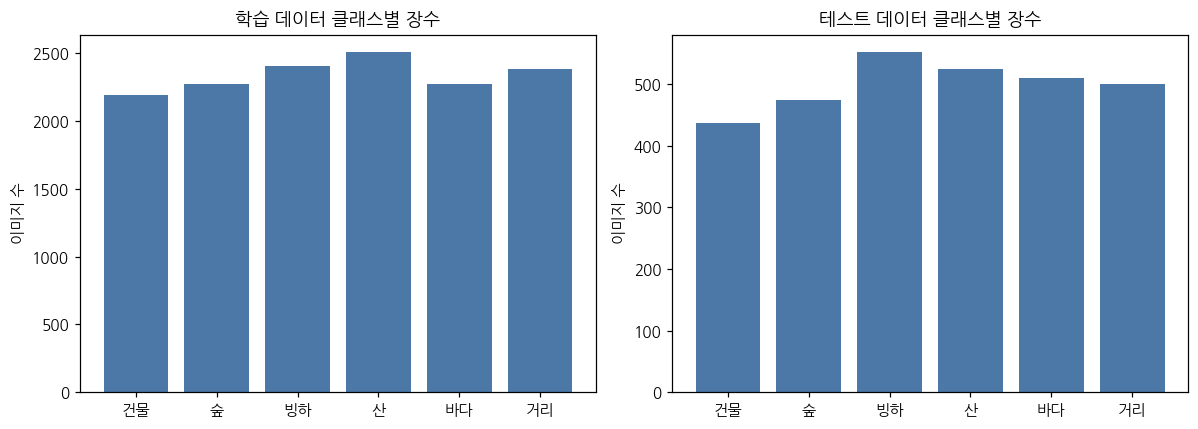

In [5]:
IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}


def count_images(class_dir: Path) -> int:
    '''한 클래스 폴더 안의 이미지 파일 개수를 셉니다.'''
    return sum(1 for p in class_dir.iterdir() if p.suffix.lower() in IMAGE_EXTS)


def summarize_split(split_dir: Path, split_name: str) -> dict:
    print("=" * 60)
    print(f"{split_name} 폴더: {split_dir}")
    print("=" * 60)
    counts = {}
    total = 0
    for cls in sorted([p.name for p in split_dir.iterdir() if p.is_dir()]):
        n = count_images(split_dir / cls)
        counts[cls] = n
        total += n
        ko = CLASS_KO.get(cls, cls)
        print(f"  - {ko:4s} ({cls:10s}): {n:5d}장")
    print(f"  합계: {total}장")
    return counts


train_counts = summarize_split(TRAIN_DIR, "학습(train)")
test_counts = summarize_split(TEST_DIR, "테스트(test)")

# 클래스별 개수를 막대그래프로 비교합니다.
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, counts, title in zip(
    axes, [train_counts, test_counts], ["학습 데이터 클래스별 장수", "테스트 데이터 클래스별 장수"]
):
    labels_ko = [CLASS_KO.get(k, k) for k in counts]
    ax.bar(labels_ko, list(counts.values()), color="#4C78A8")
    ax.set_title(title)
    ax.set_ylabel("이미지 수")
    ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()


## 2~4단계. 학습/테스트 데이터 불러오기, 150×150 리사이즈, 정규화

`image_dataset_from_directory`는 **폴더 이름을 정답 라벨**로 사용합니다.  
`image_size=(150, 150)`으로 크기를 맞추고, 모델 안의 `Rescaling(1/255)`로 픽셀을 0~1로 바꿉니다.

학습 폴더의 20%는 **검증 데이터**로 떼어, 학습 그래프의 검증 정확도를 그립니다.  
테스트 폴더는 마지막 평가 전용입니다.


In [6]:
def make_dataset(directory: Path, subset=None, shuffle=True):
    '''폴더에서 이미지를 읽어 150x150 텐서 배치를 만듭니다.'''
    kwargs = dict(
        directory=str(directory),
        image_size=(IMG_SIZE, IMG_SIZE),  # 3) 150×150 리사이즈
        batch_size=BATCH_SIZE,
        label_mode="int",                 # 정수 라벨 → sparse_categorical_crossentropy
        shuffle=shuffle,
        seed=SEED,
    )
    if subset is not None:
        kwargs["validation_split"] = VAL_SPLIT
        kwargs["subset"] = subset
    return keras.utils.image_dataset_from_directory(**kwargs)


# 2) 학습 데이터와 테스트 데이터를 불러옵니다.
train_ds = make_dataset(TRAIN_DIR, subset="training", shuffle=True)
val_ds = make_dataset(TRAIN_DIR, subset="validation", shuffle=True)
# 테스트는 순서를 고정해야 혼동행렬의 정답과 예측이 같은 순서가 됩니다.
test_ds = make_dataset(TEST_DIR, subset=None, shuffle=False)

class_names = train_ds.class_names  # 보통 알파벳 순: buildings, forest, ...
class_names_ko = [CLASS_KO.get(n, n) for n in class_names]
print("클래스 순서(모델 출력 인덱스):")
for i, (en, ko) in enumerate(zip(class_names, class_names_ko)):
    print(f"  {i} → {ko} ({en})")

# 정규화 전후 픽셀 범위를 확인합니다. (4) 픽셀 값 정규화
normalization_layer = layers.Rescaling(1.0 / 255.0)
for images, labels in train_ds.take(1):
    print("\n정규화 전 픽셀 범위: "
          f"{float(tf.reduce_min(images)):.1f} ~ {float(tf.reduce_max(images)):.1f}")
    scaled = normalization_layer(images)
    print("정규화 후 픽셀 범위: "
          f"{float(tf.reduce_min(scaled)):.3f} ~ {float(tf.reduce_max(scaled)):.3f}")
    print("배치 모양(이미지):", images.shape, "/ 라벨:", labels.shape)

# 입출력 파이프라인을 미리 준비해 학습을 조금 빠르게 합니다.
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)
test_ds = test_ds.prefetch(AUTOTUNE)

if QUICK_MODE:
    print(f"\nQUICK_MODE=True → 학습 {QUICK_TRAIN_BATCHES}배치, 검증 {QUICK_VAL_BATCHES}배치만 사용합니다.")
    print("전체 데이터로 학습하려면 설정 셀에서 QUICK_MODE = False 로 바꾸세요.")
    train_ds = train_ds.take(QUICK_TRAIN_BATCHES).prefetch(AUTOTUNE)
    val_ds = val_ds.take(QUICK_VAL_BATCHES).prefetch(AUTOTUNE)


Found 14034 files belonging to 6 classes.
Using 11228 files for training.
Found 14034 files belonging to 6 classes.
Using 2806 files for validation.
Found 3000 files belonging to 6 classes.
클래스 순서(모델 출력 인덱스):
  0 → 건물 (buildings)
  1 → 숲 (forest)
  2 → 빙하 (glacier)
  3 → 산 (mountain)
  4 → 바다 (sea)
  5 → 거리 (street)

정규화 전 픽셀 범위: 0.0 ~ 255.0
정규화 후 픽셀 범위: 0.000 ~ 1.000
배치 모양(이미지): (32, 150, 150, 3) / 라벨: (32,)

QUICK_MODE=True → 학습 120배치, 검증 30배치만 사용합니다.
전체 데이터로 학습하려면 설정 셀에서 QUICK_MODE = False 로 바꾸세요.


### 학습 이미지 미리보기

모델에 들어가기 전에, 리사이즈된 이미지가 사람과 눈으로 구분이 되는지 확인합니다.


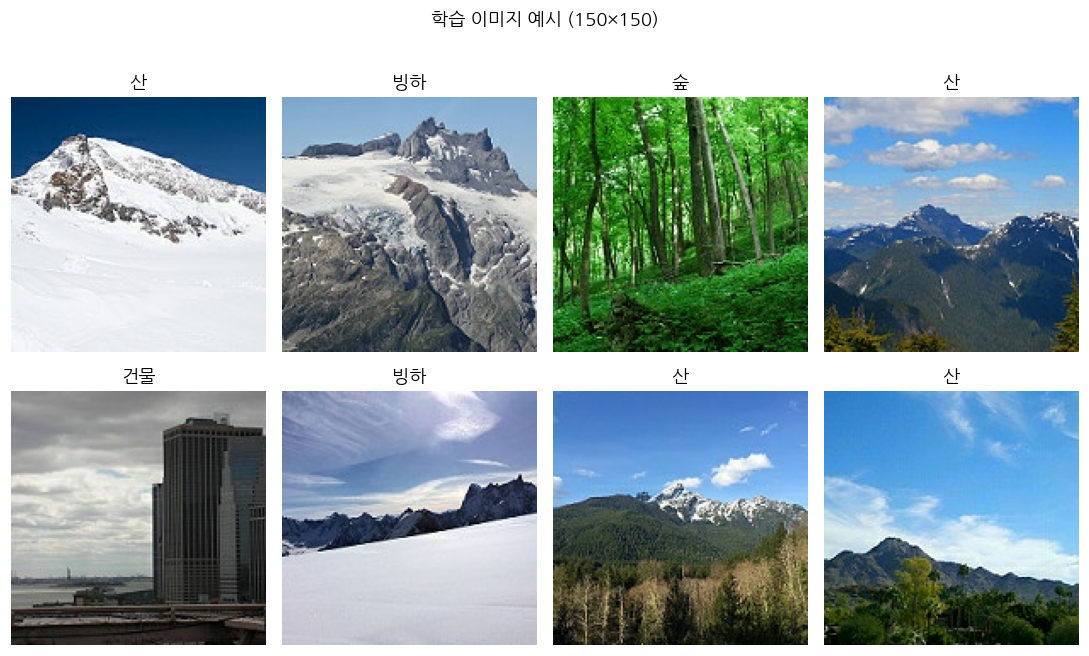

In [7]:
plt.figure(figsize=(10, 6))
for images, labels in train_ds.take(1):
    for i in range(8):
        ax = plt.subplot(2, 4, i + 1)
        # image_dataset_from_directory는 0~255 float32를 반환합니다.
        plt.imshow(images[i].numpy().astype("uint8"))
        ko = CLASS_KO.get(class_names[int(labels[i])], class_names[int(labels[i])])
        plt.title(ko)
        plt.axis("off")
plt.suptitle("학습 이미지 예시 (150×150)", y=1.02)
plt.tight_layout()
plt.show()


## 5단계. CNN 모델 생성

CNN은 이미지가 가진 **지역적인 패턴**(가장자리, 질감, 색 덩어리)을 필터로 찾아 클래스를 구분합니다.

| 층 | 역할 |
|----|------|
| Rescaling | 픽셀을 0~1로 정규화 (저장되는 모델에 포함) |
| Conv2D | 작은 필터로 특징 맵을 추출 |
| MaxPooling2D | 크기를 줄여 계산량을 낮추고 위치 변화에 조금 더 둔감하게 함 |
| GlobalAveragePooling2D | Flatten보다 파라미터가 적어 CPU 학습에 유리 |
| Dense + softmax | 6개 클래스 확률로 변환 |

GPU가 없어도 돌아가도록 필터 수를 32→64→128로 작게 두었습니다.


In [8]:
NUM_CLASSES = len(class_names)

model = keras.Sequential(
    [
        # 입력 크기: 가로 150, 세로 150, 색상 채널 3(RGB)
        layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3)),
        # 4) 픽셀 정규화: 0~255 → 0~1. 학습·예측 때 같은 전처리가 적용됩니다.
        layers.Rescaling(1.0 / 255.0, name="normalize"),
        # 첫 번째 합성곱 블록
        layers.Conv2D(32, (3, 3), activation="relu", padding="same", name="conv1"),
        layers.MaxPooling2D((2, 2), name="pool1"),
        # 두 번째 합성곱 블록
        layers.Conv2D(64, (3, 3), activation="relu", padding="same", name="conv2"),
        layers.MaxPooling2D((2, 2), name="pool2"),
        # 세 번째 합성곱 블록
        layers.Conv2D(128, (3, 3), activation="relu", padding="same", name="conv3"),
        layers.MaxPooling2D((2, 2), name="pool3"),
        # Flatten 대신 GAP: 채널별 평균만 남기므로 파라미터가 적습니다.
        layers.GlobalAveragePooling2D(name="gap"),
        layers.Dense(64, activation="relu", name="fc1"),
        layers.Dropout(0.3, name="dropout"),  # 과적합을 조금 줄입니다.
        layers.Dense(NUM_CLASSES, activation="softmax", name="pred"),
    ],
    name="nature_cnn",
)

model.summary()


Model: "nature_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ normalize (Rescaling)           │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1 (Conv2D)                  │ (None, 150, 150, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool1 (MaxPooling2D)            │ (None, 75, 75, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2 (Conv2D)                  │ (None, 75, 75, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool2 (MaxPooling2D)            │ (None, 37, 37, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3 (Conv2D)                  │ (None, 37, 37, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool3 (MaxPooling2D)            │ (None, 18, 18, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gap (GlobalAveragePooling2D)    │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fc1 (Dense)                     │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pred (Dense)                    │ (None, 6)              │           390 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,894 (398.02 KB)

 Trainable params: 101,894 (398.02 KB)

 Non-trainable params: 0 (0.00 B)

## 6단계. 모델 컴파일과 학습

- 손실: `sparse_categorical_crossentropy` (정수 라벨 + softmax)
- 최적화: Adam
- 지표: Accuracy
- `EarlyStopping`: 검증 정확도가 나아지지 않으면 학습을 일찍 멈춥니다.


In [9]:
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

early_stop = keras.callbacks.EarlyStopping(
    monitor="val_accuracy",
    patience=3,                 # 3 에포크 동안 검증 정확도가 오르지 않으면 중단
    restore_best_weights=True,  # 가장 좋았던 가중치로 되돌림
    verbose=1,
)

print("학습을 시작합니다. QUICK_MODE =", QUICK_MODE)
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=[early_stop],
    verbose=1,
)
print("학습 종료")


학습을 시작합니다. QUICK_MODE = True
Epoch 1/8
120/120 ━━━━━━━━━━━━━━━━━━━━ 22s 109ms/step - accuracy: 0.3615 - loss: 1.4887 - val_accuracy: 0.4677 - val_loss: 1.2291
Epoch 2/8
120/120 ━━━━━━━━━━━━━━━━━━━━ 5s 42ms/step - accuracy: 0.4586 - loss: 1.2207 - val_accuracy: 0.4698 - val_loss: 1.1084
Epoch 3/8
120/120 ━━━━━━━━━━━━━━━━━━━━ 4s 31ms/step - accuracy: 0.4797 - loss: 1.1355 - val_accuracy: 0.4865 - val_loss: 1.0720
Epoch 4/8
120/120 ━━━━━━━━━━━━━━━━━━━━ 4s 31ms/step - accuracy: 0.5128 - loss: 1.0824 - val_accuracy: 0.5219 - val_loss: 1.0343
Epoch 5/8
120/120 ━━━━━━━━━━━━━━━━━━━━ 4s 31ms/step - accuracy: 0.5411 - loss: 1.0480 - val_accuracy: 0.5531 - val_loss: 0.9970
Epoch 6/8
120/120 ━━━━━━━━━━━━━━━━━━━━ 4s 31ms/step - accuracy: 0.5685 - loss: 1.0013 - val_accuracy: 0.5875 - val_loss: 0.9730
Epoch 7/8
120/120 ━━━━━━━━━━━━━━━━━━━━ 4s 31ms/step - accuracy: 0.6029 - loss: 0.9599 - val_accuracy: 0.5667 - val_loss: 1.0253
Epoch 8/8
120/120 ━━━━━━━━━━━━━━━━━━━━ 4s 31ms/step - accuracy: 0.6245 - 

## 7단계. 학습 정확도와 검증 정확도 그래프

- 두 곡선이 함께 올라가면 학습이 잘 되고 있는 상태입니다.
- 학습 정확도만 높고 검증 정확도가 낮으면 **과적합**입니다.
- 둘 다 낮으면 모델이 너무 작거나, 학습이 부족한 상태입니다.


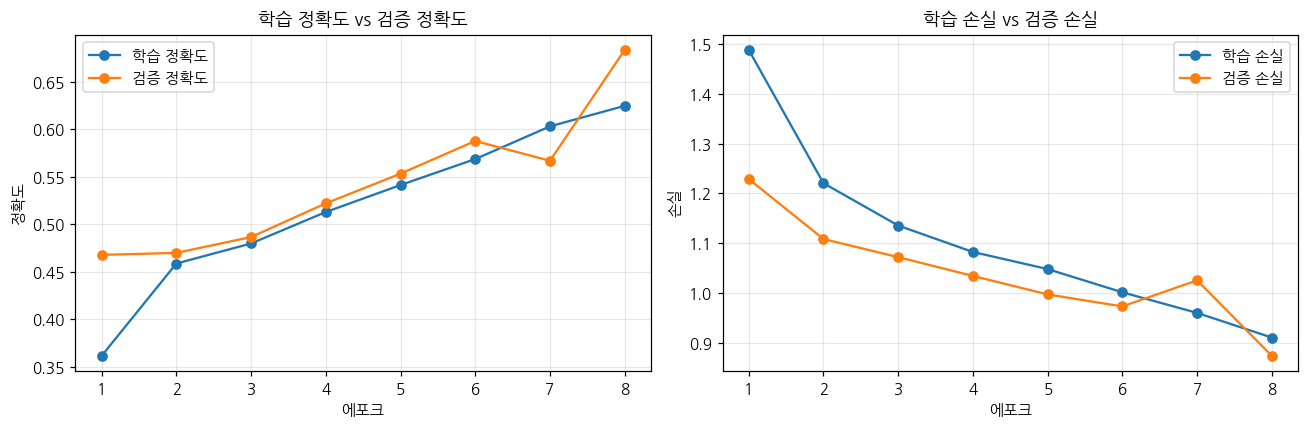

마지막 학습 정확도: 0.6245
마지막 검증 정확도: 0.6833
최고 검증 정확도: 0.6833 (에포크 8)


In [10]:
hist = history.history
epochs_ran = range(1, len(hist["accuracy"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(epochs_ran, hist["accuracy"], marker="o", label="학습 정확도")
axes[0].plot(epochs_ran, hist["val_accuracy"], marker="o", label="검증 정확도")
axes[0].set_title("학습 정확도 vs 검증 정확도")
axes[0].set_xlabel("에포크")
axes[0].set_ylabel("정확도")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(epochs_ran, hist["loss"], marker="o", label="학습 손실")
axes[1].plot(epochs_ran, hist["val_loss"], marker="o", label="검증 손실")
axes[1].set_title("학습 손실 vs 검증 손실")
axes[1].set_xlabel("에포크")
axes[1].set_ylabel("손실")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

print(f"마지막 학습 정확도: {hist['accuracy'][-1]:.4f}")
print(f"마지막 검증 정확도: {hist['val_accuracy'][-1]:.4f}")
print(f"최고 검증 정확도: {max(hist['val_accuracy']):.4f} "
      f"(에포크 {int(np.argmax(hist['val_accuracy'])) + 1})")


## 8단계. 테스트 데이터 Accuracy

테스트 이미지는 학습·검증에 쓰지 않은 데이터입니다.  
이 숫자가 서비스에 올렸을 때 기대할 수 있는 대략적인 성능입니다.


In [11]:
test_loss, test_acc = model.evaluate(test_ds, verbose=1)
print("=" * 50)
print(f"테스트 손실     : {test_loss:.4f}")
print(f"테스트 Accuracy : {test_acc:.4f} ({test_acc * 100:.2f}%)")
print("=" * 50)

# 혼동행렬·리포트용 정답/예측을 한 번에 모읍니다.
y_true = np.concatenate([labels.numpy() for _, labels in test_ds])
y_prob = model.predict(test_ds, verbose=1)
y_pred = np.argmax(y_prob, axis=1)

# evaluate와 같은지 한 번 더 확인합니다.
acc_check = accuracy_score(y_true, y_pred)
print(f"직접 계산한 Accuracy: {acc_check:.4f}")
print("\n클래스별 정밀도/재현율/F1")
print(
    classification_report(
        y_true,
        y_pred,
        target_names=class_names_ko,
        digits=3,
    )
)


94/94 ━━━━━━━━━━━━━━━━━━━━ 10s 105ms/step - accuracy: 0.6573 - loss: 0.8647
테스트 손실     : 0.8647
테스트 Accuracy : 0.6573 (65.73%)
94/94 ━━━━━━━━━━━━━━━━━━━━ 3s 26ms/step
직접 계산한 Accuracy: 0.6573

클래스별 정밀도/재현율/F1
              precision    recall  f1-score   support

          건물      0.450     0.558     0.498       437
           숲      0.921     0.880     0.900       474
          빙하      0.699     0.609     0.651       553
           산      0.759     0.533     0.626       525
          바다      0.620     0.743     0.676       510
          거리      0.580     0.629     0.603       501

    accuracy                          0.657      3000
   macro avg      0.672     0.659     0.659      3000
weighted avg      0.675     0.657     0.660      3000



## 9단계. 테스트 이미지 10장: 실제 클래스 vs 예측 클래스

초록 제목은 정답, 빨강 제목은 오분류입니다.  
오분류 이미지를 보면 “왜 헷갈렸는지”를 기획 관점으로 설명할 수 있습니다.


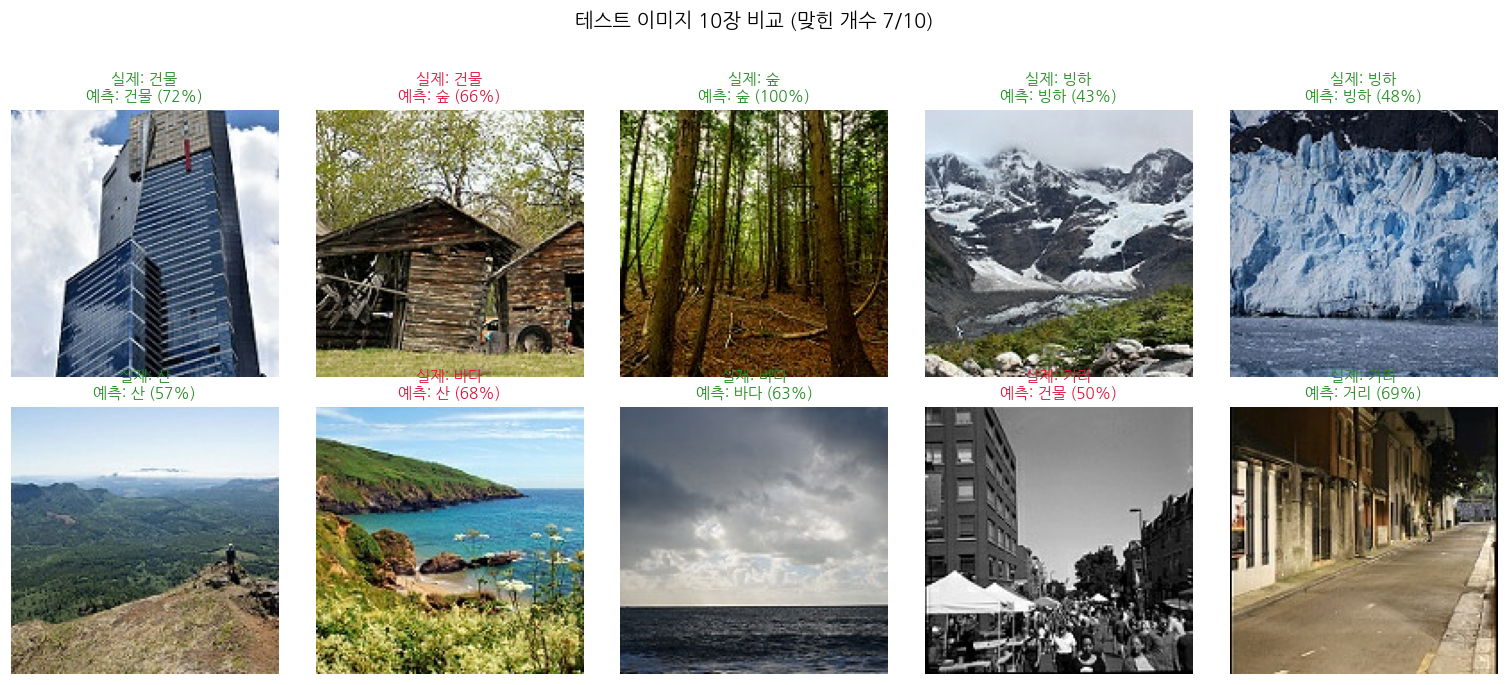

In [12]:
# 테스트셋 앞쪽만 보면 한 클래스에 치우칠 수 있어, 인덱스를 고르게 뽑습니다.
n_show = 10
n_total = len(y_true)
pick_idx = np.linspace(0, n_total - 1, n_show, dtype=int)
want = set(int(i) for i in pick_idx)

# shuffle=False 이므로 순서대로 돌며 필요한 10장만 모읍니다.
picked = {}
seen = 0
for images, _ in test_ds:
    batch = images.numpy()
    for j in range(len(batch)):
        if seen in want:
            picked[seen] = batch[j]
        seen += 1
    if len(picked) >= n_show:
        break

fig, axes = plt.subplots(2, 5, figsize=(14, 6))
axes = axes.ravel()
correct_n = 0

for i, idx in enumerate(pick_idx):
    ax = axes[i]
    ax.imshow(picked[int(idx)].astype("uint8"))
    true_ko = class_names_ko[int(y_true[idx])]
    pred_ko = class_names_ko[int(y_pred[idx])]
    conf = float(np.max(y_prob[idx])) * 100
    ok = int(y_true[idx]) == int(y_pred[idx])
    correct_n += int(ok)
    color = "forestgreen" if ok else "crimson"
    ax.set_title(f"실제: {true_ko}\n예측: {pred_ko} ({conf:.0f}%)", color=color, fontsize=10)
    ax.axis("off")

plt.suptitle(f"테스트 이미지 10장 비교 (맞힌 개수 {correct_n}/10)", y=1.03, fontsize=13)
plt.tight_layout()
plt.show()


## 10단계. 혼동행렬 시각화

행은 **실제 클래스**, 열은 **모델이 예측한 클래스**입니다.  
대각선이 진할수록 잘 맞춘 것이고, 대각선 밖 큰 숫자는 자주 혼동하는 쌍입니다.


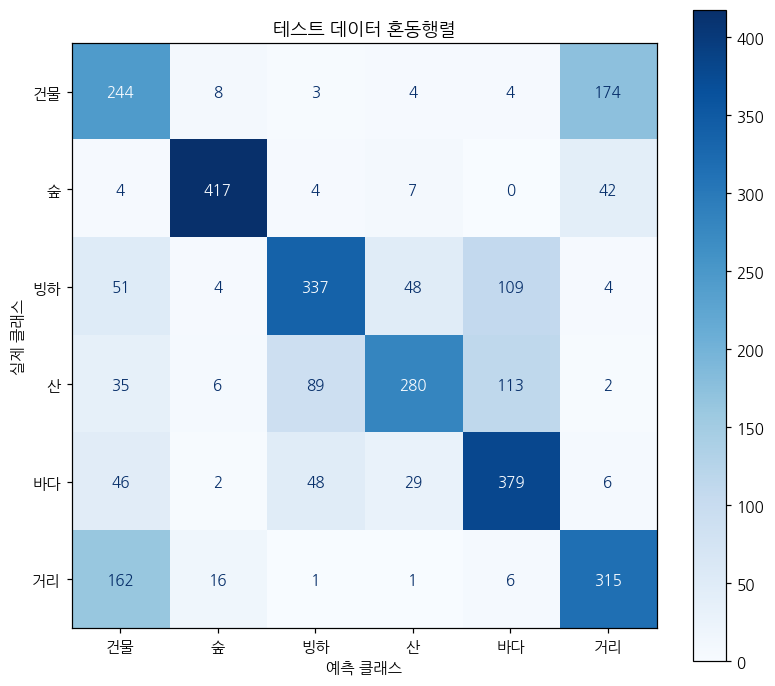

오분류가 많은 실제→예측 쌍 (상위 5개)
  건물 → 거리 : 174장
  거리 → 건물 : 162장
  산 → 바다 : 113장
  빙하 → 바다 : 109장
  산 → 빙하 : 89장


In [13]:
cm = confusion_matrix(y_true, y_pred)

fig, ax = plt.subplots(figsize=(7.5, 6.5))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names_ko)
disp.plot(ax=ax, cmap="Blues", colorbar=True, xticks_rotation=0)
ax.set_title("테스트 데이터 혼동행렬")
ax.set_xlabel("예측 클래스")
ax.set_ylabel("실제 클래스")
plt.tight_layout()
plt.show()

# 가장 많이 틀린 클래스 쌍을 출력합니다.
pairs = []
for i in range(len(class_names_ko)):
    for j in range(len(class_names_ko)):
        if i != j and cm[i, j] > 0:
            pairs.append((cm[i, j], class_names_ko[i], class_names_ko[j]))
pairs.sort(reverse=True)

print("오분류가 많은 실제→예측 쌍 (상위 5개)")
if not pairs:
    print("  오분류가 없습니다.")
else:
    for n, a, b in pairs[:5]:
        print(f"  {a} → {b} : {n}장")


## 11단계. 학습된 모델 저장

Keras 권장 포맷인 `.keras`로 저장합니다. Colab에서는 왼쪽 파일창에서 다운로드할 수 있습니다.


In [14]:
save_path = Path("nature_classifier.keras")
model.save(save_path)
print("저장 완료:", save_path.resolve())
print("파일 크기(MB):", round(save_path.stat().st_size / (1024 * 1024), 2))

# 저장 파일이 다시 열리는지 확인합니다.
reloaded = keras.models.load_model(save_path)
print("불러오기 성공:", reloaded.name)

if IN_COLAB:
    try:
        from google.colab import files
        files.download(str(save_path))
        print("Colab 다운로드 창을 열었습니다.")
    except Exception as exc:
        print("자동 다운로드 실패. 왼쪽 파일창에서 nature_classifier.keras 를 받아 주세요.", exc)


저장 완료: /content/nature_classifier.keras
파일 크기(MB): 1.21
불러오기 성공: nature_cnn


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Colab 다운로드 창을 열었습니다.


## 12단계. 정확도와 오분류 사례 분석

아래 셀은 **방금 학습한 결과 숫자**를 읽어 자동으로 해석합니다.  
Intel 자연환경 데이터에서 흔히 나타나는 혼동 패턴과 함께 읽어 주세요.


In [15]:
print("=" * 60)
print("성능 요약")
print("=" * 60)
print(f"- 테스트 Accuracy : {test_acc * 100:.2f}%")
print(f"- 최고 검증 정확도 : {max(hist['val_accuracy']) * 100:.2f}%")
print(f"- 학습 모드        : {'빠른 실습(일부 배치)' if QUICK_MODE else '전체 학습 데이터'}")
print(f"- 실제 학습 에포크 : {len(hist['accuracy'])} / 설정 {EPOCHS}")

# 클래스별 재현율(실제 그 클래스 중 맞춘 비율)
row_sum = cm.sum(axis=1)
recall = np.divide(np.diag(cm), row_sum, out=np.zeros(len(row_sum), dtype=float), where=row_sum != 0)
best_i = int(np.argmax(recall))
worst_i = int(np.argmin(recall))
print(f"- 가장 잘 맞춘 클래스 : {class_names_ko[best_i]} (재현율 {recall[best_i]*100:.1f}%)")
print(f"- 가장 못 맞춘 클래스 : {class_names_ko[worst_i]} (재현율 {recall[worst_i]*100:.1f}%)")

print("\n" + "=" * 60)
print("오분류 해석 (이 데이터에서 자주 나오는 이유)")
print("=" * 60)
tips = [
    "1) 빙하 ↔ 산",
    "   만년설이 덮인 산과 빙하는 색(흰·회색)과 질감이 비슷합니다.",
    "   간단한 CNN은 '흰색 덩어리 + 하늘'만 보고 두 클래스를 자주 섞습니다.",
    "",
    "2) 건물 ↔ 거리",
    "   거리 사진에도 건물이 함께 찍히는 경우가 많습니다.",
    "   모델이 '도시 장면'은 알아도, 주피사체가 건물인지 도로인지 헷갈립니다.",
    "",
    "3) 바다 ↔ 빙하",
    "   넓은 수평선, 단색에 가까운 면, 하늘 비율이 비슷하면 혼동할 수 있습니다.",
    "",
    "4) 숲",
    "   녹색 질감이 뚜렷해 보통 가장 구분하기 쉬운 클래스입니다.",
]
print("\n".join(tips))

gap = hist["accuracy"][-1] - hist["val_accuracy"][-1]
print("\n학습 곡선 해석")
if gap > 0.10:
    print(f"- 학습 정확도가 검증보다 {gap*100:.1f}%p 높아 과적합 징후가 있습니다.")
    print("  → Dropout 강화, 데이터 증강, 더 많은 학습 이미지가 도움이 됩니다.")
elif hist["val_accuracy"][-1] < 0.60:
    print("- 검증 정확도가 낮습니다. 에포크를 늘리거나 QUICK_MODE를 False로 두세요.")
else:
    print("- 학습/검증 정확도 차이가 크지 않아, 현재 모델 용량 대비 학습은 안정적입니다.")

print("\n서비스 관점 메모")
print("- 80% 전후라도 '자동 초안 태그 + 사람이 수정' 워크플로에는 쓸 수 있습니다.")
print("- 빙하/산처럼 헷갈리는 쌍은 화면에서 상위 2개 확률을 함께 보여주는 것이 안전합니다.")
if QUICK_MODE:
    print("- 지금 숫자는 빠른 실습 모드 기준입니다. 서비스 성능 보고서는 QUICK_MODE=False로 다시 학습하세요.")


성능 요약
- 테스트 Accuracy : 65.73%
- 최고 검증 정확도 : 68.33%
- 학습 모드        : 빠른 실습(일부 배치)
- 실제 학습 에포크 : 8 / 설정 8
- 가장 잘 맞춘 클래스 : 숲 (재현율 88.0%)
- 가장 못 맞춘 클래스 : 산 (재현율 53.3%)

오분류 해석 (이 데이터에서 자주 나오는 이유)
1) 빙하 ↔ 산
   만년설이 덮인 산과 빙하는 색(흰·회색)과 질감이 비슷합니다.
   간단한 CNN은 '흰색 덩어리 + 하늘'만 보고 두 클래스를 자주 섞습니다.

2) 건물 ↔ 거리
   거리 사진에도 건물이 함께 찍히는 경우가 많습니다.
   모델이 '도시 장면'은 알아도, 주피사체가 건물인지 도로인지 헷갈립니다.

3) 바다 ↔ 빙하
   넓은 수평선, 단색에 가까운 면, 하늘 비율이 비슷하면 혼동할 수 있습니다.

4) 숲
   녹색 질감이 뚜렷해 보통 가장 구분하기 쉬운 클래스입니다.

학습 곡선 해석
- 학습/검증 정확도 차이가 크지 않아, 현재 모델 용량 대비 학습은 안정적입니다.

서비스 관점 메모
- 80% 전후라도 '자동 초안 태그 + 사람이 수정' 워크플로에는 쓸 수 있습니다.
- 빙하/산처럼 헷갈리는 쌍은 화면에서 상위 2개 확률을 함께 보여주는 것이 안전합니다.
- 지금 숫자는 빠른 실습 모드 기준입니다. 서비스 성능 보고서는 QUICK_MODE=False로 다시 학습하세요.


## 13단계. 자연환경 이미지 자동 분류 AI 서비스 기획 요약

### 서비스명
**SceneTag** — 사진 한 장으로 자연·도시 장면을 자동 분류하고 태그를 다는 보조 AI

### 해결하려는 문제
여행 앱, 콘텐츠 플랫폼, 공공 아카이브에는 매일 수많은 풍경 사진이 올라옵니다.  
사람이 건물/숲/빙하/산/바다/거리 태그를 달면 비용과 시간이 들고, 태그 기준도 사람마다 달라집니다.

### 타깃 사용자
- 1차: 여행·사진 앱 운영자, 콘텐츠 에디터 (대량 태깅)
- 2차: 교육 콘텐츠 제작자, 관광 홍보 담당자
- 최종 소비자: 장면 태그로 사진을 검색하는 일반 사용자

### AI가 하는 일 / 사람이 하는 일
| 구분 | 내용 |
|------|------|
| AI | 업로드 이미지를 150×150으로 맞추고 6개 장면 확률을 계산 |
| AI | 가장 높은 확률의 태그를 초안으로 제시, 불확실하면 2순위 태그도 제시 |
| 사람 | 확률이 낮거나 빙하/산처럼 혼동하기 쉬운 건 검수 후 확정 |
| 사람 | 신규 클래스(사막, 야경 등) 정책과 금칙 장면 기준을 정함 |

### 핵심 사용 흐름
1. 사용자가 사진 업로드 (또는 갤러리에서 일괄 선택)
2. 전처리: 리사이즈 150×150, 0~1 정규화 (저장된 모델에 포함)
3. CNN이 6클래스 확률 출력
4. 화면: 대표 태그 + 신뢰도 + (선택) 비슷한 장면 추천
5. 검수자가 틀린 태그만 수정 → 수정 로그는 다음 재학습 데이터로 활용

### 성공 지표(KPI)
- 분류 품질: 테스트 Accuracy, 클래스별 재현율 (특히 빙하/산)
- 운영: 장당 추론 시간, 일일 처리량
- 업무: 에디터의 태그 수정률, 검수 시간 감소율
- 사용자: 태그 검색 클릭률, 검색 이탈률

### 현재 모델의 한계와 가드레일
- 한계: 단순 CNN이라 빙하↔산, 건물↔거리 혼동이 남을 수 있음. 학습 이미지를 줄인 `QUICK_MODE` 성능은 서비스 공칭 성능으로 쓰면 안 됨.
- 가드레일: 최대 확률이 낮으면 “확신 부족”으로 표시하고 자동 게시하지 않음. 사람·민감 장면은 이 모델 범위 밖.

### 다음 개선 (기획 백로그)
1. 전이학습(MobileNet 등)으로 정확도를 올리되, 모바일/웹 추론 속도를 함께 측정
2. 데이터 증강(좌우반전, 밝기)으로 과적합 완화
3. 사용자 수정 태그를 재학습 파이프라인에 연결
4. 클래스 확장 전에 “기타/모름” 클래스를 두어 오탐을 줄임

### 한 줄 포지셔닝
> SceneTag는 풍경 사진을 **즉시 6가지 장면으로 초안 분류**해, 사람이 모든 장에 태그를 달던 작업을 **검수 중심으로 바꿔 주는** 분류 AI입니다.


## 산출물 체크리스트

과제 최종 산출물에 대한 위치 안내입니다.

| 산출물 | 이 노트북에서 |
|--------|----------------|
| 실행 가능한 Python 코드 | 위 셀 전체 (Colab에서 위에서 아래로 실행) |
| CNN 모델 구조 | 5단계 `model.summary()` |
| 학습 및 검증 그래프 | 7단계 정확도·손실 곡선 |
| 테스트 정확도와 혼동행렬 | 8단계 숫자, 10단계 그림 |
| 이미지별 예측 결과 | 9단계 10장 비교 |
| 모델 파일 | `nature_classifier.keras` |
| 서비스 기획 요약 | 13단계 |

**실행 팁**
1. Colab GPU를 켜면 전체 데이터 학습(`QUICK_MODE = False`)도 현실적입니다.
2. 한글이 깨지면 0-1 셀 실행 → 런타임 재시작 → 다시 0-1부터 실행합니다.
3. 데이터 경로 오류가 나면 0-4 셀이 출력하는 해결 방법을 그대로 따르면 됩니다.
